# Capping outliers with pandas

This notebook demonstrates outlier capping, also called censoring, with the Breast Cancer Wisconsin dataset. Instead of deleting unusual observations, we replace values outside selected limits with the nearest limit.

We compare limits from the normal distribution, the IQR proximity rule, and quantiles. Capping keeps every row, which is useful when rare observations may contain important medical information.

## Learning goals

- Understand the difference between trimming and capping.
- Calculate limits from training data only.
- Apply pandas clip without changing the number of rows.
- Compare normal, IQR, and quantile limits visually.
- Keep feature rows aligned with target labels.

Capping is not automatically correct. An extreme value may be an error, a valid rare case, or a meaningful diagnosis signal. Investigate the domain before changing it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
sns.set_theme(style='whitegrid',context='notebook')

## 1. Load and split the data

The dataset contains numerical measurements computed from breast-cell images. The target is a diagnosis label, but this notebook focuses on the distribution of one feature: worst smoothness. We split first so that all capping limits are learned from the training data only.

In [2]:
breast_cancer=load_breast_cancer(as_frame=True)
X=breast_cancer.data.copy()
y=breast_cancer.target.copy()
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.30,random_state=0,stratify=y)
variable='worst smoothness'
print('Full feature shape:',X.shape)
print('Training shape:',X_train.shape)
print('Test shape:',X_test.shape)
display(X_train.head())
display(X_train[variable].describe().to_frame())

Full feature shape: (569, 30)
Training shape: (398, 30)
Test shape: (171, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
246,13.20,17.43,84.13,541.6,0.07215,0.04524,0.043360,0.011050,0.1487,0.05635,...,13.94,27.82,88.28,602.0,0.11010,0.15080,0.22980,0.04970,0.2767,0.07198
232,11.22,33.81,70.79,386.8,0.07780,0.03574,0.004967,0.006434,0.1845,0.05828,...,12.36,41.78,78.44,470.9,0.09994,0.06885,0.02318,0.03002,0.2911,0.07307
15,14.54,27.54,96.73,658.8,0.11390,0.15950,0.163900,0.073640,0.2303,0.07077,...,17.46,37.13,124.10,943.2,0.16780,0.65770,0.70260,0.17120,0.4218,0.13410
128,15.10,16.39,99.58,674.5,0.11500,0.18070,0.113800,0.085340,0.2001,0.06467,...,16.11,18.33,105.90,762.6,0.13860,0.28830,0.19600,0.14230,0.2590,0.07779
262,17.29,22.13,114.40,947.8,0.08999,0.12730,0.096970,0.075070,0.2108,0.05464,...,20.39,27.24,137.90,1295.0,0.11340,0.28670,0.22980,0.15280,0.3067,0.07484


,worst smoothness
count,398.000000
mean,0.131962
std,0.022780
min,0.081250
25%,0.115825
50%,0.130200
75%,0.145900
max,0.222600


## 2. Visualise the feature before capping

The boxplot highlights potential extremes and the histogram shows the overall distribution. A plot helps us decide whether a statistical rule is reasonable, but it cannot decide whether an observation is medically or scientifically valid.

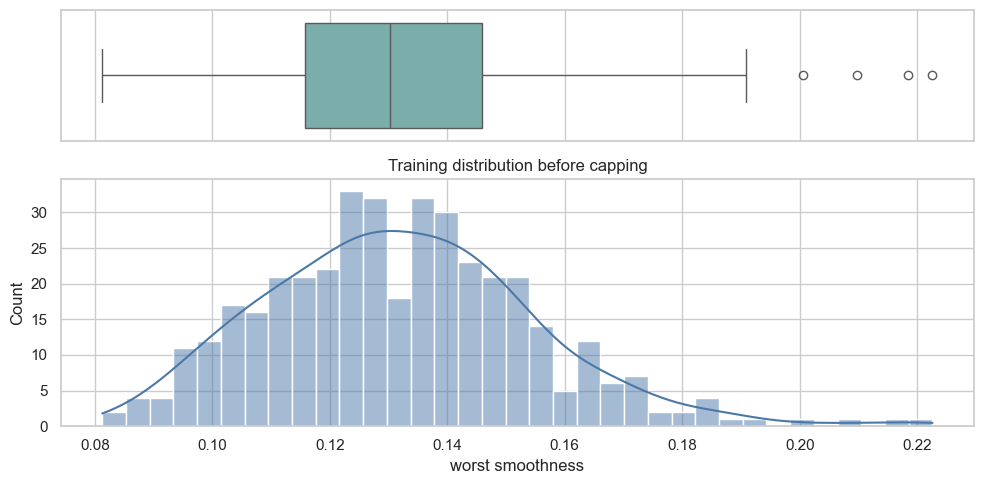

In [3]:
def plot_boxplot_and_hist(frame,variable,title=None):
    fig,(ax_box,ax_hist)=plt.subplots(2,1,sharex=True,figsize=(10,5),gridspec_kw={'height_ratios':(.45,.85)})
    sns.boxplot(x=frame[variable],ax=ax_box,color='#72B7B2')
    sns.histplot(data=frame,x=variable,bins=35,kde=True,ax=ax_hist,color='#4C78A8')
    ax_box.set(xlabel=''); ax_hist.set_title(title or variable)
    plt.tight_layout(); plt.show()
plot_boxplot_and_hist(X_train,variable,'Training distribution before capping')

## 3. Normal-distribution limits

The normal rule uses mean plus or minus a multiple of the standard deviation. A multiplier of 3 is a common starting point. It assumes that a feature is reasonably bell-shaped, so always inspect the plot before relying on this rule.

Normal limits: 0.06362 to 0.20030
Rows before and after: (398, 30) (398, 30)


,before,after
minimum,0.08125,0.081250
maximum,0.22260,0.200301


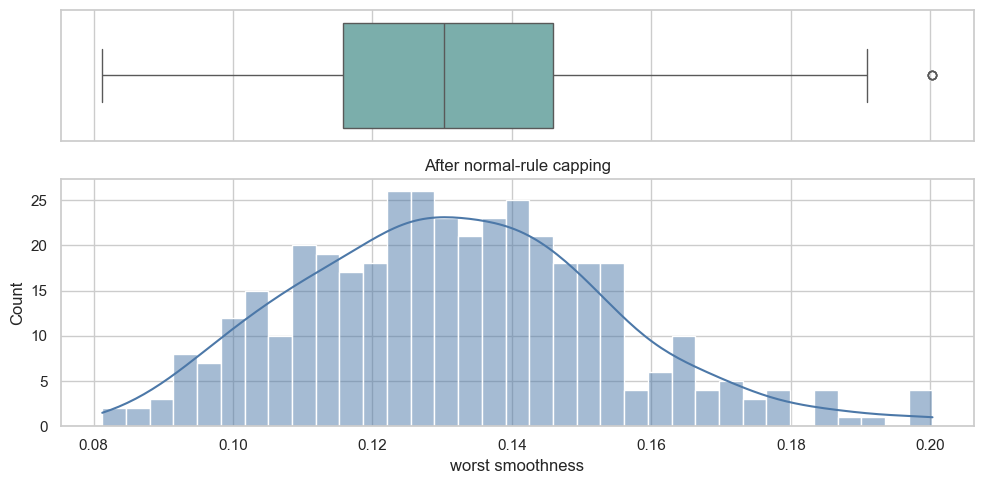

In [4]:
def gaussian_limits(frame,variable,fold=3.0):
    mean=frame[variable].mean()
    std=frame[variable].std()
    return mean-fold*std,mean+fold*std

def cap_values(frame,variable,lower,upper):
    result=frame.copy()
    result[variable]=result[variable].clip(lower=lower,upper=upper)
    return result

lower_normal,upper_normal=gaussian_limits(X_train,variable,fold=3)
X_train_normal=cap_values(X_train,variable,lower_normal,upper_normal)
X_test_normal=cap_values(X_test,variable,lower_normal,upper_normal)
print(f'Normal limits: {lower_normal:.5f} to {upper_normal:.5f}')
print('Rows before and after:',X_train.shape,X_train_normal.shape)
display(pd.DataFrame({'before':[X_train[variable].min(),X_train[variable].max()],'after':[X_train_normal[variable].min(),X_train_normal[variable].max()]},index=['minimum','maximum']))
plot_boxplot_and_hist(X_train_normal,variable,'After normal-rule capping')

## 4. IQR proximity limits

The interquartile range is Q3 minus Q1. The IQR rule uses Q1 minus a multiple of IQR as the lower limit and Q3 plus that multiple as the upper limit. A fold of 1.5 is conventional; a larger fold is less aggressive.

IQR limits: 0.07071 to 0.19101


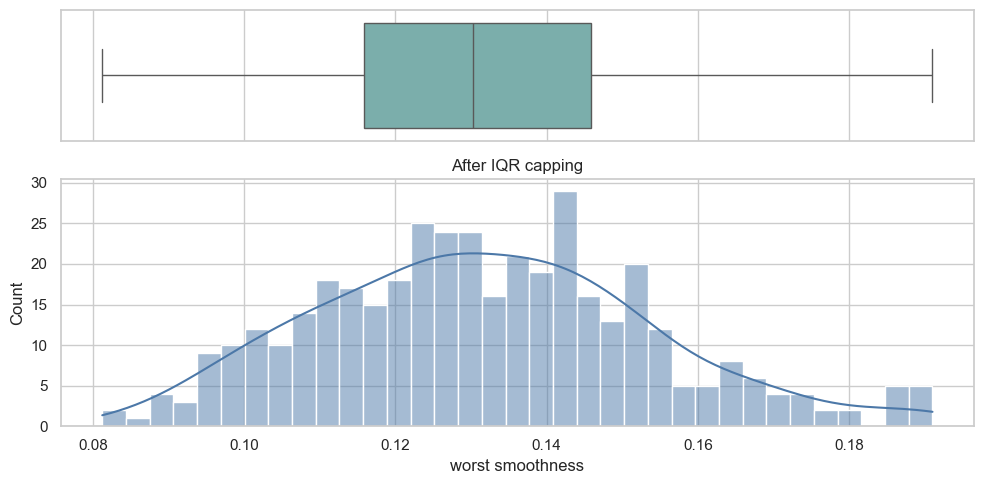

In [5]:
def iqr_limits(frame,variable,fold=1.5):
    q1=frame[variable].quantile(.25)
    q3=frame[variable].quantile(.75)
    iqr=q3-q1
    return q1-fold*iqr,q3+fold*iqr

lower_iqr,upper_iqr=iqr_limits(X_train,variable,fold=1.5)
X_train_iqr=cap_values(X_train,variable,lower_iqr,upper_iqr)
X_test_iqr=cap_values(X_test,variable,lower_iqr,upper_iqr)
print(f'IQR limits: {lower_iqr:.5f} to {upper_iqr:.5f}')
plot_boxplot_and_hist(X_train_iqr,variable,'After IQR capping')

## 5. Quantile limits

Quantile capping chooses the percentage of observations allowed in the tails. Here, the 5th and 95th training percentiles become the limits. This retains all rows but forces the lowest and highest values into the selected boundary.

Quantile limits: 0.09710 to 0.17030


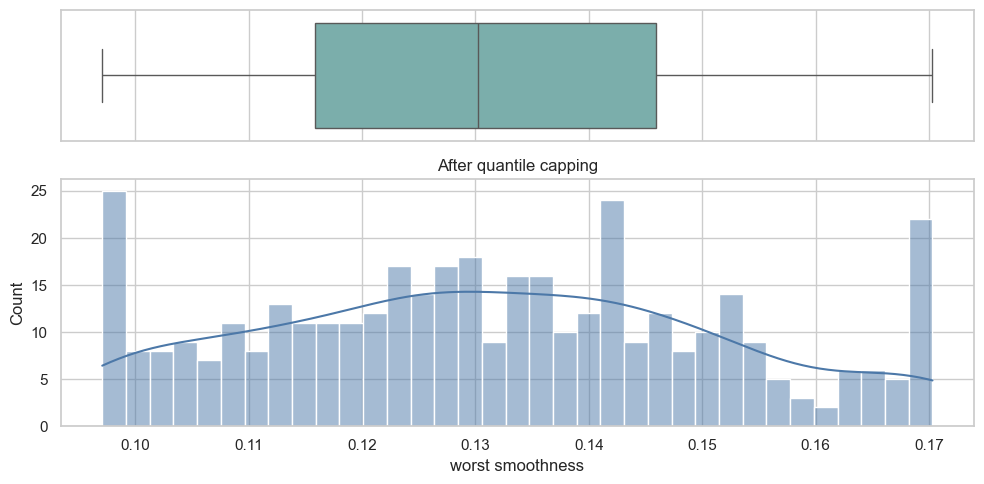

In [6]:
def quantile_limits(frame,variable,lower_quantile=.05,upper_quantile=.95):
    return frame[variable].quantile(lower_quantile),frame[variable].quantile(upper_quantile)

lower_quantile,upper_quantile=quantile_limits(X_train,variable,.05,.95)
X_train_quantile=cap_values(X_train,variable,lower_quantile,upper_quantile)
X_test_quantile=cap_values(X_test,variable,lower_quantile,upper_quantile)
print(f'Quantile limits: {lower_quantile:.5f} to {upper_quantile:.5f}')
plot_boxplot_and_hist(X_train_quantile,variable,'After quantile capping')

## 6. Compare the three rules

The limits are different because each method describes an extreme in a different way. The normal rule uses mean and spread, the IQR rule uses the middle half of the data, and quantiles explicitly control the tail percentage.

,method,lower_limit,upper_limit
0,Normal (fold=3),0.06362,0.20030
1,IQR (fold=1.5),0.07071,0.19101
2,Quantiles (5%-95%),0.09710,0.17030


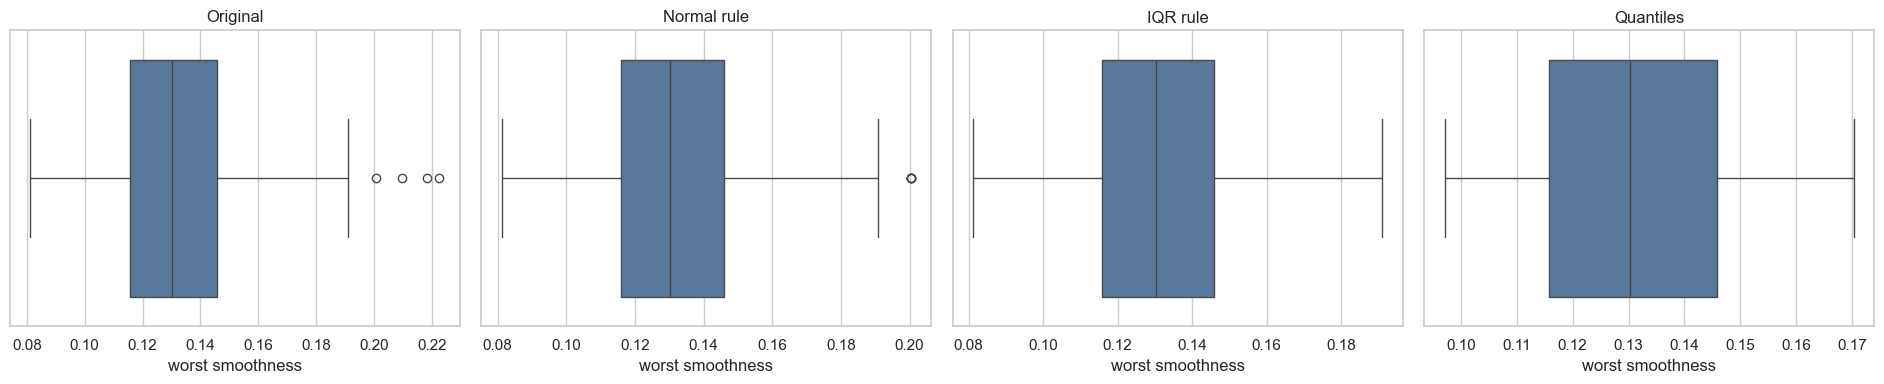

In [7]:
comparison=pd.DataFrame({
    'method':['Normal (fold=3)','IQR (fold=1.5)','Quantiles (5%-95%)'],
    'lower_limit':[lower_normal,lower_iqr,lower_quantile],
    'upper_limit':[upper_normal,upper_iqr,upper_quantile],
})
display(comparison.round(5))

fig,axes=plt.subplots(1,4,figsize=(19,4))
for ax,frame,title in zip(axes,[X_train,X_train_normal,X_train_iqr,X_train_quantile],['Original','Normal rule','IQR rule','Quantiles']):
    sns.boxplot(x=frame[variable],ax=ax,color='#4C78A8'); ax.set_title(title); ax.set_xlabel(variable)
plt.tight_layout(); plt.show()

## 7. Count values affected by capping

Capping does not remove rows. It changes only values below the lower limit or above the upper limit. Counting changed cells makes the effect transparent and is useful for monitoring a production transformation.

In [8]:
def count_changed(original,capped,variable):
    return int(original[variable].ne(capped[variable]).sum())

impact=pd.DataFrame({
    'method':['Normal','IQR','Quantiles'],
    'training_values_changed':[count_changed(X_train,X_train_normal,variable),count_changed(X_train,X_train_iqr,variable),count_changed(X_train,X_train_quantile,variable)],
    'test_values_changed':[count_changed(X_test,X_test_normal,variable),count_changed(X_test,X_test_iqr,variable),count_changed(X_test,X_test_quantile,variable)],
})
impact['training_percentage']=100*impact['training_values_changed']/len(X_train)
impact['test_percentage']=100*impact['test_values_changed']/len(X_test)
display(impact.round(2))

,method,training_values_changed,test_values_changed,training_percentage,test_percentage
0,Normal,4,0,1.01,0.00
1,IQR,4,0,1.01,0.00
2,Quantiles,39,22,9.80,12.87


## 8. Keep X and y aligned

Unlike trimming, capping keeps the number of rows unchanged. This means y_train and y_test remain aligned automatically. If a later workflow trims rows, use the same Boolean mask on X and y.

In [9]:
assert X_train.shape==X_train_normal.shape==X_train_iqr.shape==X_train_quantile.shape
assert X_test.shape==X_test_normal.shape==X_test_iqr.shape==X_test_quantile.shape
assert len(y_train)==len(X_train) and len(y_test)==len(X_test)
print('All feature and target rows remain aligned.')
print('Training target shape:',y_train.shape,'Test target shape:',y_test.shape)

All feature and target rows remain aligned.
Training target shape: (398,) Test target shape: (171,)


## Practical guidance

- Keep a valid rare observation when it contains important information, especially in medical or fraud problems.
- Correct or remove a value when it is impossible or clearly a data-entry error.
- Use capping when a valid extreme should remain but should have less influence on a sensitive model.
- Fit limits on training data only and reuse the same limits for future data.
- Compare capping with a baseline and inspect model metrics after the transformation.
- Record the rule, fold or quantiles, and number of changed values so the process is auditable.

## Summary

This notebook used pandas clip to cap values using normal-distribution, IQR, and quantile limits. Capping preserves every observation, unlike trimming, but it changes the extreme values. The safest workflow is to investigate the domain, fit limits on training data only, apply the same limits to later data, and report exactly how many values changed.